کتابخانه‌های پیش نیاز برای این ابزار را نصب کنید 

In [5]:
pip install matplotlib pyadi-iio matplotlib numpy pandas

Note: you may need to restart the kernel to use updated packages.


#    دستورات زیر برای شناسایی ماژول پلوتو با کامپیوتر است و باید در ترمینال اجرا شود    

sudo apt update
sudo apt install -y git cmake build-essential pkg-config libiio-dev libad9361-dev libsoapysdr-dev

cd ~
git clone https://github.com/pothosware/SoapyPlutoSDR.git
cd SoapyPlutoSDR
mkdir build
cd build
cmake ..
make -j$(nproc)
sudo make install
sudo ldconfig

SoapySDRUtil --find

## خروجی دستور زیر اتصال پلوتو به کامپیوتر را نشان می‌دهد
SoapySDRUtil --probe="driver=plutosdr"

# نمایش سیگنال وای فای

مشاهده سیگنال وای فای با استفاده از ادام پلوتو 

نرخ نمونه برداری با توجه به نرخ نایکویست تنظیم شود.

فرکانس مرکزی بر اساس فرستنده تنظیم شود.

پهنای باند سیگنال دریافتی که همان پهنای باند فیلتر اولیه ما نیز هست باید تنظیم شود. 
معمولا از بافر استفاده می‌شود و با توجه به این که سیگنال‌های دریافت شده در بازه زمانی خاصی ارسال می‌شود لازم است که از مقدار بافر یا حافظه موقت کافی استفاده شود.


In [14]:
import time
import adi
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# Configure Pluto SDR
sdr = adi.Pluto("ip:192.168.2.1")
%sdr.sample_rate = int(20e6)
%sdr.rx_lo = int(2437e6)
sdr.rx_rf_bandwidth = int(20e6)
sdr.rx_buffer_size = 1024 * 64

fig, ax = plt.subplots(figsize=(10, 5))

try:
    while True:
        samples = sdr.rx()

        ax.clear()
        ax.specgram(
            samples,
            NFFT=1024,
            ## fill the required Sampling freq
            Fs=,
            ##
            Fc=sdr.rx_lo,
            sides="twosided",
        )
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Frequency [Hz]")
        ax.set_title("Live WiFi OFDM Spectrogram")
        ax.grid(True)

        # Clear the notebook output cell and redraw the updated figure inline
        clear_output(wait=True)
        display(fig)
        time.sleep(0.01)

except KeyboardInterrupt:
    print("Stopped live capture.")
    plt.close(fig)

SyntaxError: expected argument value expression (2810814335.py, line 24)

In [15]:
pip install pyadi-iio

Note: you may need to restart the kernel to use updated packages.


Sweeping 21 frequencies from 1.84 GHz to 1.86 GHz...
Frequency: 1840.0 MHz | Peak Power: 104.35 dB
Frequency: 1841.0 MHz | Peak Power: 102.95 dB
Frequency: 1842.0 MHz | Peak Power: 101.73 dB
Frequency: 1843.0 MHz | Peak Power: 98.16 dB
Frequency: 1844.0 MHz | Peak Power: 102.16 dB
Frequency: 1845.0 MHz | Peak Power: 98.48 dB
Frequency: 1846.0 MHz | Peak Power: 106.04 dB
Frequency: 1847.0 MHz | Peak Power: 103.80 dB
Frequency: 1848.0 MHz | Peak Power: 108.98 dB
Frequency: 1849.0 MHz | Peak Power: 106.68 dB
Frequency: 1850.0 MHz | Peak Power: 102.83 dB
Frequency: 1851.0 MHz | Peak Power: 101.00 dB
Frequency: 1852.0 MHz | Peak Power: 101.33 dB
Frequency: 1853.0 MHz | Peak Power: 100.97 dB
Frequency: 1854.0 MHz | Peak Power: 103.43 dB
Frequency: 1855.0 MHz | Peak Power: 101.61 dB
Frequency: 1856.0 MHz | Peak Power: 102.19 dB
Frequency: 1857.0 MHz | Peak Power: 103.20 dB
Frequency: 1858.0 MHz | Peak Power: 102.25 dB
Frequency: 1859.0 MHz | Peak Power: 100.52 dB
Frequency: 1860.0 MHz | Peak 

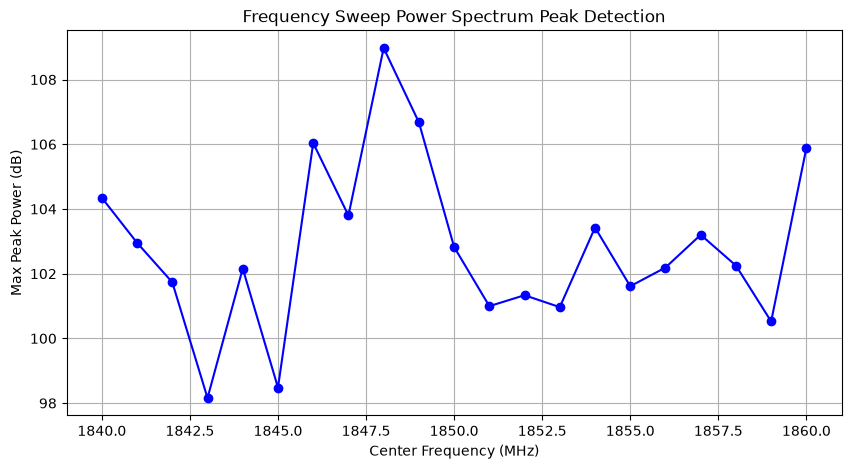

In [23]:
import adi
import numpy as np
import matplotlib.pyplot as plt

# 1. Initialize PlutoSDR
sdr = adi.Pluto("ip:192.168.2.1")

# 2. Configure Radio Parameters
sample_rate = int(1920000)      # 1.92 MSPS
bandwidth = int(1400000)        # 1.4 MHz RF bandwidth
sdr.sample_rate = sample_rate
sdr.rx_rf_bandwidth = bandwidth
sdr.gain_control_mode_chan0 = "slow_attack"
sdr.rx_buffer_size = 4096

# 3. Define Frequency Sweep Range (e.g., LTE Band 3 Downlink sub-range: 1.84 GHz to 1.86 GHz)
start_freq = 1840000000
stop_freq = 1860000000
step_size = 1000000             # 1 MHz steps
frequencies = np.arange(start_freq, stop_freq + step_size, step_size)

peak_powers = []
detected_peaks = []

print(f"Sweeping {len(frequencies)} frequencies from {start_freq/1e9} GHz to {stop_freq/1e9} GHz...")

# 4. Sweep Loop
for freq in frequencies:
    sdr.rx_lo = int(freq)
    
    # Capture samples
    samples = sdr.rx()
    
    # Compute Power Spectral Density (PSD) using FFT
    fft_result = np.fft.fftshift(np.fft.fft(samples))
    psd = 10 * np.log10(np.abs(fft_result)**2 + 1e-12)
    
    # Find peak power in the current captured window
    max_power = np.max(psd)
    peak_powers.append(max_power)
    
    print(f"Frequency: {freq/1e6:.1f} MHz | Peak Power: {max_power:.2f} dB")

# 5. Plot Power Sweep Results
plt.figure(figsize=(10, 5))
plt.plot(frequencies / 1e6, peak_powers, marker='o', color='b')
plt.title("Frequency Sweep Power Spectrum Peak Detection")
plt.xlabel("Center Frequency (MHz)")
plt.ylabel("Max Peak Power (dB)")
plt.grid(True)
plt.show()

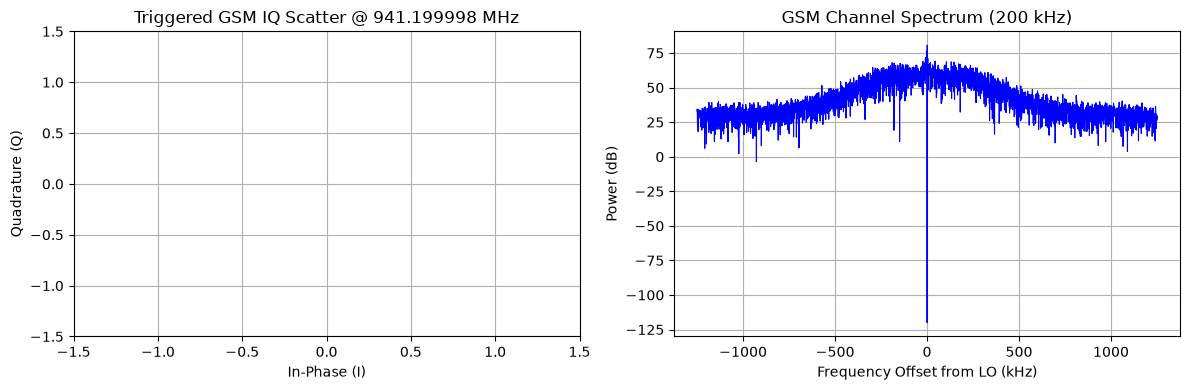

ERROR: READ LINE: -32
ERROR: READ INTEGER: -32


BrokenPipeError: [Errno 32] Broken pipe